- 선생님 문제풀이
1. 데이터 불러오기
2. 데이터 종류확인(unique)
3. 데이터 전처리
4. 데이터 분리
5. 파이프라인 생성 - 실행파일 생성
6. 예측 predict
7. 확률 if
8. 정확도
9. 모델저장

In [86]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import cross_validate,StratifiedKFold,GridSearchCV

In [ ]:
# 로지스틱 회귀 - 다중분류 모델을 이용해서 생선을 분류하시오.
# 다중 : 소프트맥스 사용해서 퍼센트를 구하시오.
# 무게,길이,대각선, 높이 ,넓이를 입력해서 생성을 분류해서 출력하시오.

In [ ]:
# 데이터 가져오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [ ]:
fish['Species'].unique()
#'Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt'

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [ ]:
# 데이터 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values

train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [90]:
# 정규화
ss= StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled =ss.transform(test_data)

In [91]:
# c규제
train_score= []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))

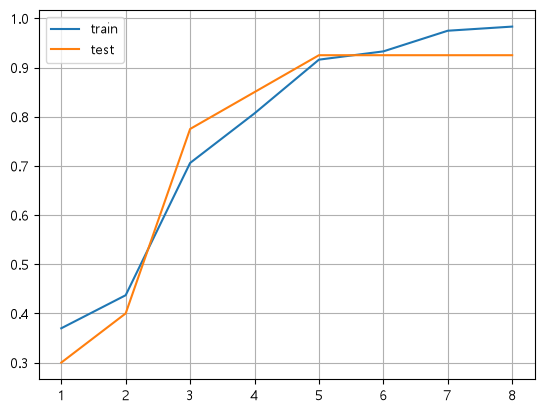

In [ ]:
# 그래프
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.legend(['train','test'])
plt.grid()
plt.show()

In [93]:
# C로 다시 학습
lr = LogisticRegression(C=20,max_iter=1000)
lr.fit(train_scaled,train_label)

#정확도
print("train정확도: ",lr.score(train_scaled,train_label))
print("test정확도: ",lr.score(test_scaled,test_label))


train정확도:  0.9327731092436975
test정확도:  0.925


In [ ]:
# 데이터 입력
in_data ='242.0,25.4,30.0,11.52,4.0200'
in_data = in_data.split(',')
in_data = list(map(float,in_data))

# 입력한 데이터 정규화
in_scaled = ss.transform([in_data])

# 예측 - 생선이름
result = lr.predict(in_scaled)

# 다중분류 : softmax
decisions = lr.decision_function(in_scaled)
soft1 = softmax(decisions,axis=1)


if result[0] =='Bream':
    result3 = soft1[0][0]
elif result[0] =='Parkki':
    result3 = soft1[0][1]
elif result[0] =='Perch':
    result3 = soft1[0][2]
elif result[0] =='Pike':
    result3 = soft1[0][3]
elif result[0] =='Roach':
    result3 = soft1[0][4]
elif result[0] =='Smelt':
    result3 = soft1[0][5]
elif result[0] =='Whitefish':
    result3 = soft1[0][6]

print("test : ",result3)
print(f'분류생선: {result3*100:.2f}%의 확률로 {result[0]}로 판별됩니다.')



test :  0.5805674618117529
분류생선: 58.06%의 확률로 Bream로 판별됩니다.


In [ ]:
#파이프라인 생성 - 실행파일 생성

from sklearn.pipeline import make_pipeline
model2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=20,max_iter=1000)
)

In [ ]:
# 모델 학습
model2.fit(train_data,train_label)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['Bream','Parkki','Perch',...,'Roach','Smelt','Whitefish']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [ ]:
# 정확도
print('train정확도: ',model2.score(train_data,train_label))
print('test정확도: ',model2.score(test_data,test_label))

train정확도:  0.9327731092436975
test정확도:  0.925


In [100]:
#저장
import joblib
joblib.dump(model2,'model2.joblib')
print('모델 저장완료')

모델 저장완료


In [ ]:
#model2저장 확인
model2 = joblib.load('model2.joblib')

in_data = '242.0,25.4,30.0,11.52,4.0200'
in_data = in_data.split(',')
in_data = list(map(float,in_data))

result = model2.predict([in_data])                                
soft1 = softmax(model2.decision_function([in_data]),axis=1)       

print(f'분류생선: {soft1[0].max()*100:.2f}%의 확률로 {result[0]}로 판별됩니다.')

분류생선: 58.06%의 확률로 Bream로 판별됩니다.
